# Risk-Managed Commodity Trading Strategy
### Trend and spread strategies on crude oil and gold, tested out-of-sample with costs and risk rules

## 1. Project Overview

This notebook tests two simple, well-known trading ideas on commodity price data and asks one question:

> **Can these strategies make money after trading costs once strict risk rules are applied, and were they tested honestly?**

| Strategy | Assets | Idea |
|---|---|---|
| **Trend following** | WTI crude, Brent crude, Gold | Hold the asset when its 20-day average price is above its 60-day average; otherwise stay out |
| **Spread mean reversion** | Brent minus WTI price gap | When the gap is unusually wide or narrow, bet it returns to normal |

**Risk rules applied on top:** volatility-targeted position sizing (10% annual risk), a drawdown circuit breaker (halve the position after a 15% fall from peak), a one-day execution delay (no look-ahead), and transaction costs.

**Honest testing:** settings are fixed in advance; results are judged on 2021 onward, a period not used to pick them. The 2014-2020 period is shown separately as a check.

> **Important:** This is an educational historical analysis, not investment advice. The prices are **spot/continuous price series, not tradable futures contracts**: there is no modelling of contract expiry, rolling, margin, slippage or real execution. A backtest does not guarantee future performance.

## 2. Notebook Map

3. **Setup**: imports and settings (Steps 1-2)
4. **Data**: load, clean, align, returns, train/test split (Steps 3-7)
5. **Strategies and risk rules**: signals, sizing, backtest engine, metrics (Steps 8-13)
6. **Results**: scoreboard, costs, robustness checks (Steps 14-17)
7. **Fundamental check**: US crude inventories vs WTI (Step 18)
8. **Charts** (Steps 19-24)
9. **Findings and limitations**

## 3. Setup

### Step 1: Import libraries

**WHAT**: Load `pandas` (data tables), `numpy` (maths), `matplotlib` and `seaborn` (charts).

**WHY**: Everything is built from first principles with basic tools, so you can explain every line. No black-box backtesting libraries.

**WATCH OUT**: If `seaborn` is missing, run `pip install seaborn` once.

In [31]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.figsize": (11, 5), "axes.titlesize": 13, "axes.titleweight": "bold"})

### Step 2: Settings (one place for every number)

**WHAT**: All strategy, risk, cost and testing settings live in this one cell.

**WHY**: Hard-coded numbers scattered through the code cause bugs and make it hard to test "what if costs double?".

**WATCH OUT**: *Overfitting.* The 20/60-day windows, 10% target volatility and -15% breaker are **conventional starting values chosen before testing, not optimised numbers**. Step 17 checks how sensitive the in-sample results are to the windows. Never change a setting after looking at the out-of-sample results.

| Setting | Meaning |
|---|---|
| `MA_FAST`, `MA_SLOW` | Short and long moving-average windows (about 1 month and 3 months of trading days) |
| `Z_WINDOW`, `Z_ENTRY`, `Z_EXIT` | Spread z-score window; enter beyond +/-2, exit inside +/-0.5 |
| `TARGET_VOL` | Annual risk each strategy is sized to (10%) |
| `VOL_WINDOW` | Days used to measure recent volatility |
| `MAX_LEVERAGE` | Cap on position size (1.5x) so calm periods do not create huge positions |
| `DD_CUT`, `DD_RECOVER` | Halve the position below -15% drawdown; restore above -7.5% |
| `COST_RATE` | 0.05% (5 basis points) cost per unit of position change |
| `SPLIT_DATE` | Out-of-sample testing starts here |

In [32]:
# Strategy settings
MA_FAST, MA_SLOW = 20, 60
Z_WINDOW, Z_ENTRY, Z_EXIT = 60, 2.0, 0.5

# Risk settings
TARGET_VOL = 0.10
VOL_WINDOW = 20
MAX_LEVERAGE = 1.5
DD_CUT, DD_RECOVER = -0.15, -0.075

# Cost and evaluation settings
COST_RATE = 0.0005
SPLIT_DATE = "2021-01-01"
RISK_FREE_RATE = 0.0
TRADING_DAYS = 252

## 4. Data

### Step 3: Load and clean the price files

**WHAT**: One function reads a CSV, converts prices to numbers (FRED marks missing days with a dot `.`, which becomes `NaN`), drops missing rows, sorts by date and removes duplicate dates.

**WHY**: Text prices cannot be used in maths, and unsorted or duplicate dates corrupt time-series calculations.

**WATCH OUT**: Do not fill missing prices with zero. A zero price would create fake -100% and +infinite returns.

| File | Content |
|---|---|
| `wti.csv` | FRED `DCOILWTICO`: WTI spot, USD per barrel |
| `brent.csv` | FRED `DCOILBRENTEU`: Brent spot, USD per barrel |
| `gold.csv` | Daily gold price in USD per ounce (columns `date`, `price`) |
| `us_inventories.csv` | Weekly US crude oil inventories (used in Step 18) |

In [33]:
def find_file(file_name):
    # Look in data/ first, then the project folder
    for folder in ["data", "."]:
        path = os.path.join(folder, file_name)
        if os.path.exists(path):
            return path
    raise FileNotFoundError(f"Could not find {file_name} in data/ or the project folder.")


def load_price_series(file_name, date_col, price_col, label):
    raw = pd.read_csv(find_file(file_name))
    missing = [c for c in (date_col, price_col) if c not in raw.columns]
    if missing:
        raise ValueError(f"{file_name}: missing columns {missing}. Found: {list(raw.columns)}")

    df = raw.copy()
    df[price_col] = pd.to_numeric(df[price_col], errors="coerce")   # "." becomes NaN
    df[date_col] = pd.to_datetime(df[date_col], errors="coerce")
    df = df.dropna(subset=[date_col, price_col])
    df = df.sort_values(date_col).drop_duplicates(subset=[date_col])

    series = df.set_index(date_col)[price_col].rename(label)
    series.index.name = "date"
    print(f"{label:6s} raw rows: {len(raw):5d} | clean rows: {len(series):5d} | "
          f"{series.index.min().date()} to {series.index.max().date()}")
    return series

In [34]:
wti = load_price_series("wti.csv", "observation_date", "DCOILWTICO", "wti")
brent = load_price_series("brent.csv", "observation_date", "DCOILBRENTEU", "brent")
gold = load_price_series("gold.csv", "date", "price", "gold")

wti    raw rows:  3131 | clean rows:  2993 | 2014-10-15 to 2026-10-14
brent  raw rows:  3327 | clean rows:  3237 | 2014-01-14 to 2026-10-14
gold   raw rows:  3018 | clean rows:  3018 | 2014-10-20 to 2026-10-20


### Step 4: The April 20, 2020 negative oil price

**WHAT**: Look at the genuine negative WTI price and decide how to treat it.

**WHY (a classic interview topic)**: On 20 April 2020 the expiring May WTI futures contract settled at about -USD 37.63, because storage at Cushing, Oklahoma was nearly full and holders of the expiring contract had to pay others to take delivery. The spot series used here shows -USD 36.98 that day.

**WATCH OUT**: The normal return formula breaks around a negative price.

$$R_t = \frac{P_t}{P_{t-1}} - 1$$

*Worked example:* 17 Apr price 18.31, 20 Apr price -36.98: return = -36.98 / 18.31 - 1 = **-302%**, which is a loss bigger than the whole position. On 21 Apr the price rebounds to 8.91, and the formula divides by a negative number: 8.91 / -36.98 - 1 = **-124%**, a **loss** even though the price rose. Both numbers are meaningless as percentage returns.

**Decision**: set the WTI and spread returns to zero on the negative-price day and the day after. **This is a modelling assumption, not the actual market P&L for those days**, so it is stated openly here and again in the limitations. Brent (prices stayed positive) and gold are unaffected. Step 11 checks what positions the strategies actually held on those two days.

In [35]:
prices_raw = pd.concat([wti, brent, gold], axis=1)
prices_raw.loc["2020-04-16":"2020-04-23"]

,wti,brent,gold
date,,,
2020-04-16,19.82,18.69,1720.400024
2020-04-17,18.31,19.75,1689.199951
2020-04-20,-36.98,17.36,1701.599976
2020-04-21,8.91,9.12,1678.199951
2020-04-22,13.64,13.77,1728.699951
2020-04-23,15.06,15.06,1733.300049


### Step 5: Align everything into one table

**WHAT**: Join WTI, Brent and Gold on dates that exist in **all three** files (an "inner join").

**WHY**: The spread needs Brent and WTI on the same day, and all strategies should be compared over identical dates.

**WATCH OUT**: US and UK holidays differ, so a few days are dropped. Check how many, and that the date range still covers the whole period.

In [36]:
prices = pd.concat([wti, brent, gold], axis=1, join="inner").sort_index()
prices.index.name = "date"

print(f"Aligned trading days: {len(prices)}")
print(f"Date range: {prices.index.min().date()} to {prices.index.max().date()}")
print(f"Days dropped by the join -> WTI: {len(wti) - len(prices)}, "
      f"Brent: {len(brent) - len(prices)}, Gold: {len(gold) - len(prices)}")
prices.head(3)

Aligned trading days: 2950
Date range: 2014-10-20 to 2026-10-14
Days dropped by the join -> WTI: 43, Brent: 287, Gold: 68


,wti,brent,gold
date,,,
2014-10-20,82.76,84.42,1244.000000
2014-10-21,83.25,85.17,1251.000000
2014-10-22,80.52,86.38,1244.800049


### Step 6: Daily returns (and the spread "return")

**WHAT**: Convert prices into daily percentage returns. For the spread strategy, build a return series from the **dollar change in the Brent-WTI gap**.

**WHY**: Strategies earn *returns*, not prices. Returns also make assets with very different price levels (oil near 80, gold near 2,000) comparable.

**Formulas and a worked example**

$$R_t = \frac{P_t}{P_{t-1}} - 1 \qquad\qquad S_t = P^{Brent}_t - P^{WTI}_t \qquad\qquad R^{spread}_t = \frac{S_t - S_{t-1}}{\bar P_{t-1}}, \;\; \bar P_{t-1} = \frac{P^{Brent}_{t-1} + P^{WTI}_{t-1}}{2}$$

- *Return:* price 80 then 84 gives 84 / 80 - 1 = **+5%**.
- *Spread return:* yesterday Brent 85, WTI 80, so spread S = 5 and average price 82.5. Today Brent 86, WTI 80.5, so S = 5.5. The gap grew by 0.50 dollars; 0.50 / 82.5 = **+0.61%** per unit. Holding "long the spread" (long Brent, short WTI) earns +0.61%; holding "short the spread" loses 0.61%.
- Dividing by the average crude price turns a dollar gap change into a percentage on the capital tied up in one barrel.

**WATCH OUT**: Divide by *yesterday's* average price, and zero out the WTI and spread returns on the days around the negative WTI price (Step 4).

In [37]:
def calculate_returns(prices):
    returns = prices.pct_change()

    # Spread return: dollar change in the Brent-WTI gap / yesterday's average crude price
    spread = prices["brent"] - prices["wti"]
    avg_price = (prices["brent"] + prices["wti"]) / 2
    returns["spread"] = spread.diff() / avg_price.shift(1)

    # Percentage returns are undefined across a non-positive price: zero WTI and spread returns that day and the next
    non_positive = prices["wti"] <= 0
    excluded_days = non_positive | non_positive.shift(1, fill_value=False)
    returns.loc[excluded_days, ["wti", "spread"]] = 0.0

    return returns.fillna(0.0), excluded_days


returns, excluded_days = calculate_returns(prices)
print("Days with WTI and spread returns set to zero:", [d.date().isoformat() for d in returns.index[excluded_days]])
returns.loc["2020-04-17":"2020-04-22"]

Days with WTI and spread returns set to zero: ['2020-04-20', '2020-04-21']


,wti,brent,gold,spread
date,,,,
2020-04-17,-0.076186,0.056715,-0.018135,0.133472
2020-04-20,0.000000,-0.121013,0.007341,0.000000
2020-04-21,0.000000,-0.474654,-0.013752,0.000000
2020-04-22,0.530864,0.509868,0.030092,-0.008874


### Step 7: Chronological train / test split

**WHAT**: Split the history at `SPLIT_DATE`. **In-sample (train)** is before it; **out-of-sample (test)** is from that date onward.

**WHY**: A strategy judged on the same data used to choose its settings looks better than it really is. The test period is the honest scorecard.

**WATCH OUT**: Never shuffle time-series data randomly. Shuffling leaks future prices into the past.

In [38]:
is_train = returns.index < SPLIT_DATE
is_test = ~is_train

for label, mask in [("In-sample (train)", is_train), ("Out-of-sample (test)", is_test)]:
    idx = returns.index[mask]
    print(f"{label:22s}: {idx.min().date()} to {idx.max().date()} ({mask.sum()} days)")

In-sample (train)     : 2014-10-20 to 2020-12-31 (1532 days)
Out-of-sample (test)  : 2021-01-04 to 2026-10-14 (1418 days)


## 5. Strategies and Risk Rules

### Step 8: Strategy 1, trend following (moving-average crossover)

**WHAT**: Hold the asset (signal 1) when the 20-day average price is above the 60-day average, otherwise stay in cash (signal 0).

**WHY**: Trend following is a standard approach in commodity funds: stay with rising markets and step aside from falling ones.

**WATCH OUT**: *Whipsaw.* Moving averages lag, so in sideways markets they flip often and lose small amounts repeatedly. Use trailing windows only (`rolling`), never centred windows.

$$\text{Signal}_t = \begin{cases} 1 & \text{if } \text{SMA}_{20}(t) > \text{SMA}_{60}(t) \\ 0 & \text{otherwise} \end{cases}$$

*Worked example:* 20-day average 75, 60-day average 70, so signal = 1 (hold). Later the 20-day falls to 68, so signal = 0 (cash).

In [39]:
def trend_signal(price, fast=MA_FAST, slow=MA_SLOW):
    fast_avg = price.rolling(fast).mean()
    slow_avg = price.rolling(slow).mean()
    return (fast_avg > slow_avg).astype(float)   # NaN during warm-up counts as 0 (cash)

### Step 9: Strategy 2, Brent-WTI spread mean reversion

**WHAT**: Track the gap between Brent and WTI. When it is unusually wide or narrow versus its recent past, bet it returns to normal.

**WHY**: Both are light crude oils linked by trade and arbitrage, so large gaps tend to shrink. Trading the *gap* removes most of the overall oil-price risk.

**WATCH OUT**: Brent and WTI are priced at different times of day (London vs New York), which can make daily spread moves look more predictable than they are. Step 17 tests this.

**Z-score formula and worked example**

$$Z_t = \frac{S_t - \text{mean}_{60}(S)}{\text{std}_{60}(S)}$$

The z-score says how many "normal wiggles" today's gap is away from its 60-day average. *Example:* average gap 4, standard deviation 1, today 6, so Z = (6 - 4) / 1 = **2** (unusually wide).

| Z-score | Meaning | Action |
|---|---|---|
| above +2 | gap too wide | short the spread (short Brent, long WTI), position -1 |
| below -2 | gap too narrow | long the spread (long Brent, short WTI), position +1 |
| between -0.5 and +0.5 | back to normal | exit to cash, position 0 |
| otherwise | in between | keep the previous position |

One barrel of Brent is hedged against one barrel of WTI (1:1).

In [40]:
def mean_reversion_signal(spread, window=Z_WINDOW, z_entry=Z_ENTRY, z_exit=Z_EXIT):
    z = (spread - spread.rolling(window).mean()) / spread.rolling(window).std()

    positions, current = [], 0.0
    for value in z:
        if np.isnan(value):
            current = 0.0
        elif value > z_entry:
            current = -1.0      # gap too wide: short the spread
        elif value < -z_entry:
            current = 1.0       # gap too narrow: long the spread
        elif abs(value) < z_exit:
            current = 0.0       # back to normal: exit
        positions.append(current)

    return pd.Series(positions, index=spread.index), z

### Step 10: Collect all signals and returns in one place

**WHAT**: Build the four strategies (three trend, one spread) as named entries, each with its signal, its return series and its cost rate.

**WHY**: One loop can then test every strategy with identical rules, which keeps the comparison fair and the code short.

**WATCH OUT**: The spread trades two legs, so its cost rate is **double** (5 basis points per leg).

In [41]:
spread = prices["brent"] - prices["wti"]
spread_position, spread_z = mean_reversion_signal(spread)

signals = {
    "WTI trend": trend_signal(prices["wti"]),
    "Brent trend": trend_signal(prices["brent"]),
    "Gold trend": trend_signal(prices["gold"]),
    "Brent-WTI spread": spread_position,
}
strategy_returns = {
    "WTI trend": returns["wti"],
    "Brent trend": returns["brent"],
    "Gold trend": returns["gold"],
    "Brent-WTI spread": returns["spread"],
}
cost_rates = {name: COST_RATE for name in signals}
cost_rates["Brent-WTI spread"] = 2 * COST_RATE

share_in_market = pd.Series({name: (sig != 0).mean() for name, sig in signals.items()})
print("Share of days each strategy holds a position:")
print((share_in_market * 100).round(1).astype(str) + "%")

Share of days each strategy holds a position:
WTI trend           51.2%
Brent trend         50.6%
Gold trend          57.6%
Brent-WTI spread    34.2%
dtype: object


### Step 11: Execution delay and volatility-targeted position sizing

**WHAT**: Two rules turn raw signals into the positions actually held.

1. **One-day delay:** a signal calculated at today's close can only be traded for tomorrow's return (`shift(1)`).
2. **Volatility targeting:** size each position so that it carries about 10% annual risk. The more an asset has been swinging, the smaller the position.

**WHY**: The delay removes look-ahead bias, the most common backtest mistake. Volatility targeting keeps risk steady, so a wild period does not dominate the results.

**WATCH OUT**: The volatility used for tomorrow's size may only use returns up to today. Weights are capped at 1.5x. Until 20 days of returns exist, no position is taken.

**Formula and worked example**

$$\sigma_{ann} = \text{std}_{20}(R) \times \sqrt{252} \qquad\qquad w_t = \min\!\left(\frac{\text{TARGET\_VOL}}{\sigma_{ann}},\; 1.5\right)$$

The $\sqrt{252}$ turns daily wiggle into yearly wiggle (about 252 trading days a year; random daily moves add up as square roots, not straight sums).

- *Stormy market:* daily standard deviation 2.0% gives 2.0% x 15.87 = 31.7% a year, so weight = 0.10 / 0.317 = **0.32** (hold 32% of capital).
- *Calm market:* daily standard deviation 0.6% gives 9.5% a year, so weight = 0.10 / 0.095 = **1.05** (hold 105%).

In [42]:
def volatility_scale(asset_returns):
    annual_vol = asset_returns.rolling(VOL_WINDOW).std() * np.sqrt(TRADING_DAYS)
    return (TARGET_VOL / annual_vol).clip(upper=MAX_LEVERAGE).fillna(0.0)


def make_weights(name, risk_managed, lag=1):
    # Raw: the signal itself (0/1 or -1/0/1). Risk-managed: signal x volatility scale.
    weights = signals[name]
    if risk_managed:
        weights = weights * volatility_scale(strategy_returns[name])
    return weights.shift(lag).fillna(0.0)    # lag=1: trade tomorrow on today's signal

In [43]:
# Check: which positions were actually held on the two excluded days in April 2020?
held = pd.DataFrame({name: make_weights(name, risk_managed=False) for name in signals})
held.loc[excluded_days]

,WTI trend,Brent trend,Gold trend,Brent-WTI spread
date,,,,
2020-04-20,0.0,0.0,1.0,0.0
2020-04-21,0.0,0.0,1.0,-1.0


> **How to read this table**: On 20 April 2020 neither oil trend strategy held a position, and the spread strategy was also flat, so excluding that day's -302% move does not hide a real loss for them. On 21 April the spread strategy was short the spread. Its dollar P&L that day would have been a very large gain (the gap collapsed by roughly USD 54), but a *percentage* return on a negative average price is undefined, so that day is excluded; leaving out a windfall is the **conservative** choice. Brent's and gold's returns are not excluded.

### Step 12: The backtest engine (costs and circuit breaker)

**WHAT**: One function runs any strategy day by day: applies the position, subtracts costs, and tracks the net equity curve and its peak. If risk rules are on, it halves the position when the equity falls more than 15% below its peak, and restores it once the fall shrinks to 7.5% or less.

**WHY**: One shared engine guarantees every strategy and every table use identical logic.

**WATCH OUT**: The breaker must look at the **net-of-cost** equity, and it only affects the *next* day's position (no look-ahead). Each test period starts with equity = 1.0.

**Formulas and worked example**

$$\text{Cost}_t = |w_t - w_{t-1}| \times \text{cost rate} \qquad\quad \text{Net return}_t = w_t \times R_t - \text{Cost}_t \qquad\quad \text{Drawdown}_t = \frac{\text{Equity}_t}{\text{Peak}_t} - 1$$

- *Cost:* moving from position 0 to 0.4 with a 0.05% rate costs 0.4 x 0.0005 = **0.02%** of capital. Small, but 100 changes a year add up.
- *Drawdown:* equity peaked at 1.20 and is now 1.02, so drawdown = 1.02 / 1.20 - 1 = **-15%**. The breaker would halve the position.

In [44]:
def run_backtest(asset_returns, weights, cost_rate, circuit_breaker):
    equity, peak, multiplier, prev_weight = 1.0, 1.0, 1.0, 0.0
    final_weights, gross_returns, net_returns = [], [], []

    for r, target_w in zip(asset_returns.values, weights.values):
        w = target_w * (multiplier if circuit_breaker else 1.0)
        cost = abs(w - prev_weight) * cost_rate
        gross = w * r
        net = gross - cost

        equity *= (1.0 + net)
        peak = max(peak, equity)
        if circuit_breaker:
            drawdown = equity / peak - 1.0
            if drawdown < DD_CUT:
                multiplier = 0.5
            elif drawdown > DD_RECOVER:
                multiplier = 1.0

        prev_weight = w
        final_weights.append(w)
        gross_returns.append(gross)
        net_returns.append(net)

    idx = asset_returns.index
    return pd.Series(final_weights, idx), pd.Series(gross_returns, idx), pd.Series(net_returns, idx)


def run_one(name, mask, risk_managed, lag=1, cost_rate=None):
    # Run one strategy on one period; risk_managed = volatility sizing + circuit breaker
    cost_rate = cost_rates[name] if cost_rate is None else cost_rate
    weights = make_weights(name, risk_managed, lag)[mask]
    return run_backtest(strategy_returns[name][mask], weights, cost_rate, circuit_breaker=risk_managed)

### Step 13: Performance metrics

**WHAT**: Summarise any return series with a standard scorecard.

| Metric | Plain-English meaning |
|---|---|
| **Total Return** | Growth of 1.00 invested at the start, minus 1 |
| **Annualized Volatility** | Daily standard deviation x $\sqrt{252}$: how bumpy the ride is |
| **Sharpe Ratio** | (average yearly return - risk-free rate) / annualized volatility: reward per unit of bumpiness |
| **Max Drawdown** | Worst peak-to-low fall of the equity curve |
| **Position Changes** | Times the position flipped between long, short and flat (not daily resizing) |
| **Avg Daily Turnover** | Average daily change in position size; this is what drives costs |

*Sharpe worked example:* 8% yearly return with 20% volatility (risk-free rate 0%) gives 8 / 20 = **0.40**. Higher is better; below about 0.5 is usually unimpressive.

**WHY**: Return alone hides risk. A strategy that earned 50% with a 53% drawdown is very different from one that earned 13% with a 16% drawdown.

**WATCH OUT**: Use 252 (trading days), not 365, for annualizing. The risk-free rate is set to 0% here, which slightly flatters Sharpe ratios.

In [45]:
def performance_metrics(net_returns, weights):
    equity = (1.0 + net_returns).cumprod()
    drawdown = equity / equity.cummax() - 1.0
    annual_vol = net_returns.std() * np.sqrt(TRADING_DAYS)
    annual_return = net_returns.mean() * TRADING_DAYS
    sharpe = (annual_return - RISK_FREE_RATE) / annual_vol if annual_vol > 0 else 0.0

    state = np.sign(weights.round(6))                      # -1, 0 or +1
    changes = int((state.diff().fillna(state.iloc[0]).abs() > 0).sum())

    return {
        "total_return": equity.iloc[-1] - 1.0,
        "ann_vol": annual_vol,
        "sharpe": sharpe,
        "max_dd": drawdown.min(),
        "changes": changes,
        "turnover": weights.diff().abs().mean(),
    }


def format_table(results):
    raw = pd.DataFrame(results).T
    table = pd.DataFrame(index=raw.index)
    table["Total Return"] = raw["total_return"].map("{:.1%}".format)
    table["Ann. Volatility"] = raw["ann_vol"].map("{:.1%}".format)
    table["Sharpe"] = raw["sharpe"].map("{:.2f}".format)
    table["Max Drawdown"] = raw["max_dd"].map("{:.1%}".format)
    table["Position Changes"] = raw["changes"].astype(int)
    table["Avg Daily Turnover"] = raw["turnover"].map("{:.1%}".format)
    return table

## 6. Results

### Step 14: Scoreboard for all strategies (after costs)

**WHAT**: Run every strategy twice, **raw** (signal only) and **risk-managed** (volatility sizing + circuit breaker), with costs, on both periods. Buy-and-hold is the benchmark for each asset.

**WHY**: Raw vs risk-managed isolates what the risk rules do. Buy-and-hold shows whether trading beat simply owning the asset. Comparing the two periods shows whether anything held up beyond the dates used to pick the settings.

**WATCH OUT**: All rows are **after costs**. Judge the **out-of-sample** table first; the in-sample table is context, not proof.

In [46]:
def evaluate_all(mask):
    results = {}
    for name in signals:
        for label, risk in [("raw", False), ("risk-managed", True)]:
            weights, gross, net = run_one(name, mask, risk)
            results[f"{name} | {label}"] = performance_metrics(net, weights)

    for asset, label in [("wti", "WTI"), ("brent", "Brent"), ("gold", "Gold")]:
        r = returns[asset][mask]
        results[f"{label} buy & hold"] = performance_metrics(r, pd.Series(1.0, index=r.index))
    return results


train_results = evaluate_all(is_train)
test_results = evaluate_all(is_test)

print("OUT-OF-SAMPLE (2021 onward), after costs")
format_table(test_results)

OUT-OF-SAMPLE (2021 onward), after costs


,Total Return,Ann. Volatility,Sharpe,Max Drawdown,Position Changes,Avg Daily Turnover
WTI trend | raw,51.1%,32.6%,0.39,-53.0%,31,2.1%
WTI trend | risk-managed,13.1%,6.6%,0.36,-15.7%,31,1.0%
Brent trend | raw,49.6%,33.0%,0.38,-61.5%,27,1.8%
Brent trend | risk-managed,13.0%,6.8%,0.36,-18.6%,27,1.0%
Gold trend | raw,85.5%,15.9%,0.77,-20.1%,30,2.1%
Gold trend | risk-managed,46.3%,9.0%,0.80,-13.7%,30,3.1%
Brent-WTI spread | raw,135.8%,18.6%,0.92,-21.0%,85,6.1%
Brent-WTI spread | risk-managed,71.1%,6.9%,1.43,-3.6%,85,4.5%
WTI buy & hold,110.8%,41.0%,0.53,-55.2%,1,0.0%
Brent buy & hold,147.1%,42.1%,0.59,-55.0%,1,0.0%


In [47]:
print("IN-SAMPLE (before 2021), after costs")
format_table(train_results)

IN-SAMPLE (before 2021), after costs


,Total Return,Ann. Volatility,Sharpe,Max Drawdown,Position Changes,Avg Daily Turnover
WTI trend | raw,1.2%,22.6%,0.12,-38.7%,27,1.8%
WTI trend | risk-managed,-9.9%,7.5%,-0.19,-16.2%,27,1.2%
Brent trend | raw,23.8%,22.4%,0.27,-30.0%,27,1.8%
Brent trend | risk-managed,8.6%,7.6%,0.22,-10.6%,27,1.2%
Gold trend | raw,32.8%,11.6%,0.46,-15.2%,28,1.8%
Gold trend | risk-managed,35.8%,8.1%,0.66,-10.5%,28,3.1%
Brent-WTI spread | raw,382.7%,28.4%,1.05,-25.1%,78,5.2%
Brent-WTI spread | risk-managed,59.1%,6.7%,1.17,-4.6%,78,2.5%
WTI buy & hold,20.1%,58.8%,0.33,-83.1%,1,0.0%
Brent buy & hold,-39.3%,55.7%,0.14,-89.5%,1,0.0%


> **How to read these tables**: Compare each strategy row with the buy-and-hold row for the same asset, on **Sharpe** and **Max Drawdown**, not only on return. A strategy that earns less but with a much smaller drawdown made a trade-off; one that earns less *and* has a lower Sharpe did not add value on a risk-adjusted basis. Then compare the two periods: a result that exists only in one period is weak evidence.

In [48]:
def yearly_returns(mask):
    table = {}
    for name in signals:
        w, g, n = run_one(name, mask, risk_managed=False)
        table[f"{name} | raw"] = n
        w, g, n = run_one(name, mask, risk_managed=True)
        table[f"{name} | risk-managed"] = n
    for asset, label in [("wti", "WTI"), ("brent", "Brent"), ("gold", "Gold")]:
        table[f"{label} buy & hold"] = returns[asset][mask]
    daily = pd.DataFrame(table)
    yearly = (1 + daily).groupby(daily.index.year).prod() - 1
    return yearly.T.apply(lambda column: column.map("{:.1%}".format))


print("Calendar-year returns, out-of-sample, after costs (2026 is a partial year)")
yearly_returns(is_test)

Calendar-year returns, out-of-sample, after costs (2026 is a partial year)


date,2021,2022,2023,2024,2025,2026
WTI trend | raw,28.4%,-7.2%,-12.4%,-2.0%,-14.5%,72.6%
WTI trend | risk-managed,13.1%,0.4%,-4.4%,-0.8%,-1.6%,6.7%
Brent trend | raw,27.8%,-6.2%,-13.8%,-12.5%,-16.4%,97.9%
Brent trend | risk-managed,14.1%,-0.2%,-3.5%,-3.0%,-2.2%,8.4%
Gold trend | raw,-4.5%,5.1%,-0.9%,20.5%,56.9%,-1.4%
Gold trend | risk-managed,-4.0%,4.0%,-3.1%,15.2%,33.1%,-1.3%
Brent-WTI spread | raw,14.7%,15.4%,15.2%,18.8%,12.0%,16.2%
Brent-WTI spread | risk-managed,11.9%,8.7%,8.8%,10.6%,10.3%,6.0%
WTI buy & hold,55.8%,6.4%,-10.3%,0.8%,-21.0%,78.0%
Brent buy & hold,50.8%,7.2%,-6.2%,-4.0%,-17.7%,106.3%


> **How to read this table**: It shows *when* each strategy made or lost money, not just the total. Look for years where a strategy lost while buy-and-hold gained (or the reverse) and ask what the market was doing: strong one-way moves usually help trend rules, choppy sideways years hurt them.

### Step 15: The four versions for the flagship strategy (WTI trend)

**WHAT**: For WTI trend, show all four combinations: raw or risk-managed, before or after costs.

**WHY**: This isolates two effects: what the **risk rules** change, and how much **trading costs** take.

**WATCH OUT**: "Pre-cost" rows are for understanding only. They are not achievable returns.

In [49]:
def four_versions(name, mask):
    w_raw, gross_raw, net_raw = run_one(name, mask, risk_managed=False)
    w_risk, gross_risk, net_risk = run_one(name, mask, risk_managed=True)
    return {
        "1. Raw, pre-cost": performance_metrics(gross_raw, w_raw),
        "2. Raw, post-cost": performance_metrics(net_raw, w_raw),
        "3. Risk-managed, pre-cost": performance_metrics(gross_risk, w_risk),
        "4. Risk-managed, post-cost": performance_metrics(net_risk, w_risk),
        "WTI buy & hold": test_results["WTI buy & hold"],
    }


four_wti = four_versions("WTI trend", is_test)
format_table(four_wti)

,Total Return,Ann. Volatility,Sharpe,Max Drawdown,Position Changes,Avg Daily Turnover
"1. Raw, pre-cost",53.5%,32.6%,0.40,-52.5%,31,2.1%
"2. Raw, post-cost",51.1%,32.6%,0.39,-53.0%,31,2.1%
"3. Risk-managed, pre-cost",13.9%,6.6%,0.38,-15.4%,31,1.0%
"4. Risk-managed, post-cost",13.1%,6.6%,0.36,-15.7%,31,1.0%
WTI buy & hold,110.8%,41.0%,0.53,-55.2%,1,0.0%


> **How to read this table**: Rows 1 vs 2 (and 3 vs 4) show the cost drag. Rows 2 vs 4 show what the risk rules did to return, volatility and drawdown. Compare all four with buy-and-hold in the last row.

### Step 16: Trading cost sensitivity

**WHAT**: Re-run the two original strategies (WTI trend and the spread) at 5, 10 and 20 basis points per unit traded (spread: per leg).

**WHY**: Real costs include slippage and are often higher than assumed. A strategy that only works at very low costs is fragile.

**WATCH OUT**: The spread trades more often and trades two legs, so it is more cost-sensitive than a slow trend rule.

In [50]:
cost_levels = {"5 bps": 0.0005, "10 bps": 0.0010, "20 bps": 0.0020}
leg_multiplier = {"WTI trend": 1, "Brent-WTI spread": 2}

rows = {}
for name, legs in leg_multiplier.items():
    for label, risk in [("raw", False), ("risk-managed", True)]:
        row = {}
        for cost_label, rate in cost_levels.items():
            w, g, n = run_one(name, is_test, risk, cost_rate=rate * legs)
            m = performance_metrics(n, w)
            row[f"Return @ {cost_label}"] = f"{m['total_return']:.1%}"
            row[f"Sharpe @ {cost_label}"] = f"{m['sharpe']:.2f}"
        rows[f"{name} | {label}"] = row

pd.DataFrame(rows).T

,Return @ 5 bps,Sharpe @ 5 bps,Return @ 10 bps,Sharpe @ 10 bps,Return @ 20 bps,Sharpe @ 20 bps
WTI trend | raw,51.1%,0.39,48.8%,0.38,44.3%,0.36
WTI trend | risk-managed,13.1%,0.36,12.3%,0.34,11.3%,0.32
Brent-WTI spread | raw,135.8%,0.92,116.2%,0.83,81.7%,0.67
Brent-WTI spread | risk-managed,71.1%,1.43,60.4%,1.26,41.0%,0.93


> **How to read this table**: Returns and Sharpe should fall as costs rise. Look at how fast: a small fall means costs are not the main risk; a steep fall means the edge is thin.

### Step 17: Robustness checks (are the results fragile?)

**WHAT**: Two honest stress tests.

1. **In-sample window check:** try other moving-average windows on **in-sample data only** (before 2021). If only the 20/60 pair works and its neighbours do not, the rule is probably a lucky fit.
2. **Extra execution delay:** trade 2 or 3 days after the signal instead of 1. A real edge should survive a short delay; an edge that vanishes after one extra day is suspicious.

**WHY**: A single good number can be luck. Showing what happens when you nudge the assumptions is how you separate a real pattern from noise.

**WATCH OUT**: The window grid uses only pre-2021 data, so the out-of-sample test stays untouched. This grid is a **sensitivity check, not a search for better settings**: do not change the settings because of it without re-planning the test.

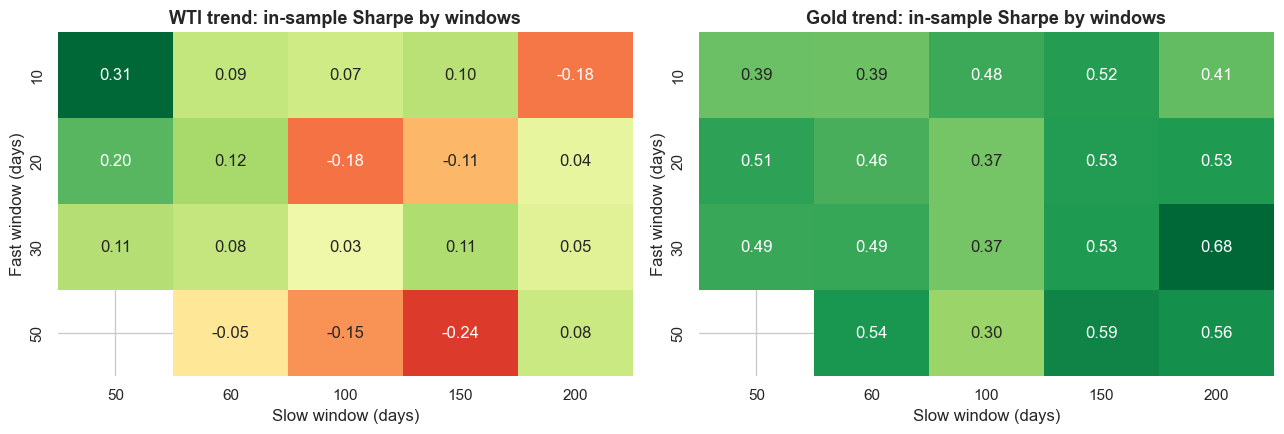

In [51]:
def sharpe_for_windows(price, asset_returns, fast, slow):
    signal = trend_signal(price, fast, slow).shift(1).fillna(0.0)
    w, g, n = run_backtest(asset_returns[is_train], signal[is_train], COST_RATE, circuit_breaker=False)
    return performance_metrics(n, w)["sharpe"]


fast_windows = [10, 20, 30, 50]
slow_windows = [50, 60, 100, 150, 200]

grids = {}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (asset, title) in zip(axes, [("wti", "WTI"), ("gold", "Gold")]):
    grid = pd.DataFrame(index=fast_windows, columns=slow_windows, dtype=float)
    for f in fast_windows:
        for s in slow_windows:
            if f < s:
                grid.loc[f, s] = sharpe_for_windows(prices[asset], returns[asset], f, s)
    grids[asset] = grid
    sns.heatmap(grid, annot=True, fmt=".2f", cmap="RdYlGn", center=0, ax=ax, cbar=False)
    ax.set_title(f"{title} trend: in-sample Sharpe by windows")
    ax.set_xlabel("Slow window (days)")
    ax.set_ylabel("Fast window (days)")
plt.tight_layout()
plt.show()

> **How to read these charts**: Each cell is the in-sample Sharpe ratio (after costs, no risk rules) for one pair of windows; green is better, red is worse. A reliable rule shows a **broad green area**. A single green cell surrounded by red or white is a warning sign.

In [52]:
delay_rows = {}
for name in signals:
    for label, risk in [("raw", False), ("risk-managed", True)]:
        row = {}
        for lag in [1, 2, 3]:
            w, g, n = run_one(name, is_test, risk, lag=lag)
            row[f"{lag}-day delay"] = f"{performance_metrics(n, w)['sharpe']:.2f}"
        delay_rows[f"{name} | {label}"] = row

print("Out-of-sample Sharpe ratio (after costs) as the execution delay grows")
pd.DataFrame(delay_rows).T

Out-of-sample Sharpe ratio (after costs) as the execution delay grows


,1-day delay,2-day delay,3-day delay
WTI trend | raw,0.39,0.34,0.32
WTI trend | risk-managed,0.36,0.37,0.34
Brent trend | raw,0.38,0.40,0.39
Brent trend | risk-managed,0.36,0.38,0.36
Gold trend | raw,0.77,0.80,0.85
Gold trend | risk-managed,0.80,0.81,0.92
Brent-WTI spread | raw,0.92,0.46,0.37
Brent-WTI spread | risk-managed,1.43,0.73,0.58


> **How to read this table**: Compare each row left to right. Slow trend rules should barely change. If a strategy's Sharpe drops sharply after one extra day, its result depends on very fast reaction or on data timing quirks, and it should be treated as **unvalidated**.

## 7. Fundamental Check: US Crude Inventories vs WTI

### Step 18: Do inventory changes line up with oil price moves?

**WHAT**: Weekly US crude inventory changes (builds are positive, draws are negative) compared with WTI returns, tested two ways.

**WHY**: Oil prices are driven by supply and demand. A build usually signals oversupply (bearish); a draw signals tight supply (bullish). Traders read the weekly report, so this connects technical strategies to a fundamental driver.

**WATCH OUT: timing.** Each row in the file is dated on the **Friday that ends the report week**, but the data is published the **following Wednesday**. So:

- **Test A (same week):** correlates the inventory change with that week's Friday-to-Friday WTI return. It describes the relationship, but it is **not tradable**, because the number was not known during that week.
- **Test B (release-day reaction):** correlates the inventory change with WTI's return on the Wednesday it was published. This is the fair test of whether the market reacts to the news.

Markets react to *surprises* versus forecasts, and no forecast data is available here, so both tests are rough.

*Reading the statistics:* **Correlation** runs from -1 to +1 (0 = no linear link); a **negative** value fits the theory (builds go with falling prices). A few extreme days can distort it, so the table also shows it **without days beyond +/-15%**, and the **Spearman** (rank) version, which one extreme day cannot dominate. A **t-statistic** divides an effect by its noise level: roughly, **above 2 in size** suggests the effect is unlikely to be chance, below 2 means it could easily be chance.

In [53]:
inventory = pd.read_csv(find_file("us_inventories.csv"), parse_dates=["date"])
inventory = inventory.sort_values("date").drop_duplicates("date").set_index("date")
change = inventory["inventory_change_million_bbl"]

# Test A: same-week Friday-to-Friday WTI return
weekly_return = wti.resample("W-FRI").last().pct_change().dropna()
test_a = pd.concat([change, weekly_return.rename("wti_return")], axis=1, join="inner")

# Test B: WTI return on the Wednesday the report was published (week-ending Friday + 5 days)
daily_return = wti.pct_change()
release_days = change.index + pd.Timedelta(days=5)
reaction = pd.Series(daily_return.reindex(release_days).values, index=change.index).dropna()
test_b = pd.concat([change, reaction.rename("wti_return")], axis=1, join="inner")


def summarize(df):
    x, y = df["inventory_change_million_bbl"], df["wti_return"]
    draws, builds = y[x < 0], y[x > 0]
    se = np.sqrt(draws.var() / len(draws) + builds.var() / len(builds))
    rank_corr = x.corr(y, method="spearman")
    rank_t = rank_corr * np.sqrt((len(df) - 2) / (1 - rank_corr ** 2))
    normal_days = y.abs() <= 0.15                      # leave out extreme days such as April 2020
    return {
        "Observations": len(df),
        "Correlation": round(x.corr(y), 3),
        "Correlation (days within +/-15%)": round(x[normal_days].corr(y[normal_days]), 3),
        "Spearman (rank) correlation": round(rank_corr, 3),
        "Spearman t-statistic": round(rank_t, 1),
        "Avg return, draw weeks": f"{draws.mean():.2%}",
        "Avg return, build weeks": f"{builds.mean():.2%}",
        "t-stat of draw minus build": round((draws.mean() - builds.mean()) / se, 2),
    }


inventory_stats = pd.DataFrame({
    "Test A: same week (not tradable)": summarize(test_a),
    "Test B: release-day reaction": summarize(test_b),
})
inventory_stats

,Test A: same week (not tradable),Test B: release-day reaction
Observations,625,616
Correlation,-0.017,-0.002
Correlation (days within +/-15%),-0.053,-0.108
Spearman (rank) correlation,-0.054,-0.148
Spearman t-statistic,-1.3,-3.7
"Avg return, draw weeks",0.61%,0.39%
"Avg return, build weeks",-0.12%,-0.12%
t-stat of draw minus build,1.32,1.73


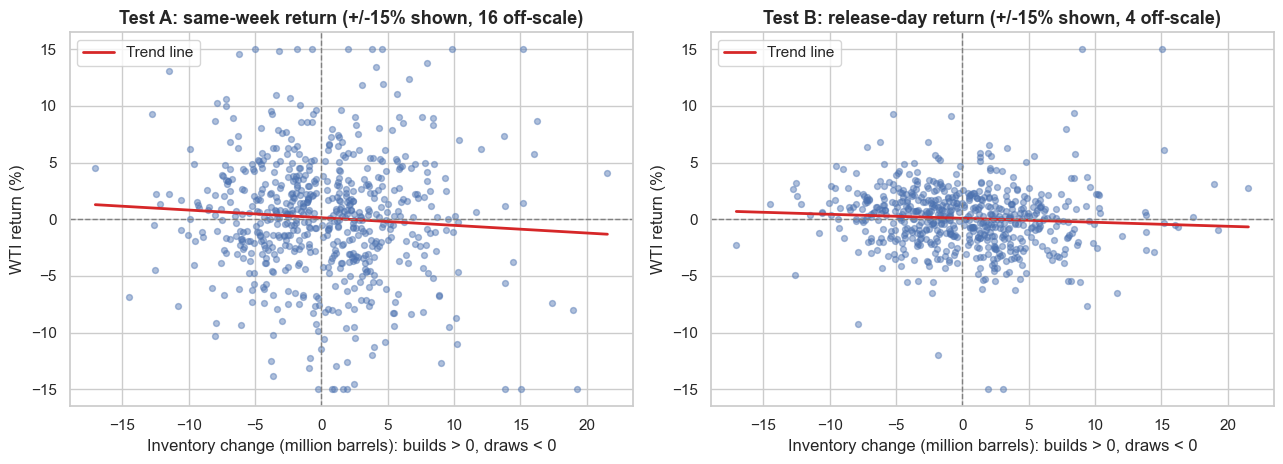

In [54]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, df, title in [(axes[0], test_a, "Test A: same-week return"),
                      (axes[1], test_b, "Test B: release-day return")]:
    x, y = df["inventory_change_million_bbl"], df["wti_return"] * 100
    ax.scatter(x, y.clip(-15, 15), alpha=0.45, s=18)
    slope, intercept = np.polyfit(x, y.clip(-15, 15), 1)
    xs = np.linspace(x.min(), x.max(), 50)
    ax.plot(xs, slope * xs + intercept, color="#d62728", lw=2, label="Trend line")
    ax.axhline(0, color="gray", ls="--", lw=1)
    ax.axvline(0, color="gray", ls="--", lw=1)
    off_scale = int((y.abs() > 15).sum())
    ax.set_title(f"{title} (+/-15% shown, {off_scale} off-scale)")
    ax.set_xlabel("Inventory change (million barrels): builds > 0, draws < 0")
    ax.set_ylabel("WTI return (%)")
    ax.legend()
plt.tight_layout()
plt.show()

> **How to read this chart**: A downward-sloping line means builds go with falling prices and draws with rising prices, as theory suggests. A flat cloud and a line near horizontal mean the raw weekly inventory number alone explains little. Extreme points beyond +/-15% are clipped on the chart only (the statistics above use all data).

## 8. Charts

### Step 19: Chart 1, WTI price with moving averages

**WHAT**: WTI price with its 20-day and 60-day averages and the train/test split line.

**WHY**: A visual check that the averages follow the price and cross at sensible points.

**WATCH OUT**: Averages must be trailing (`rolling`), never centred, otherwise they peek into the future.

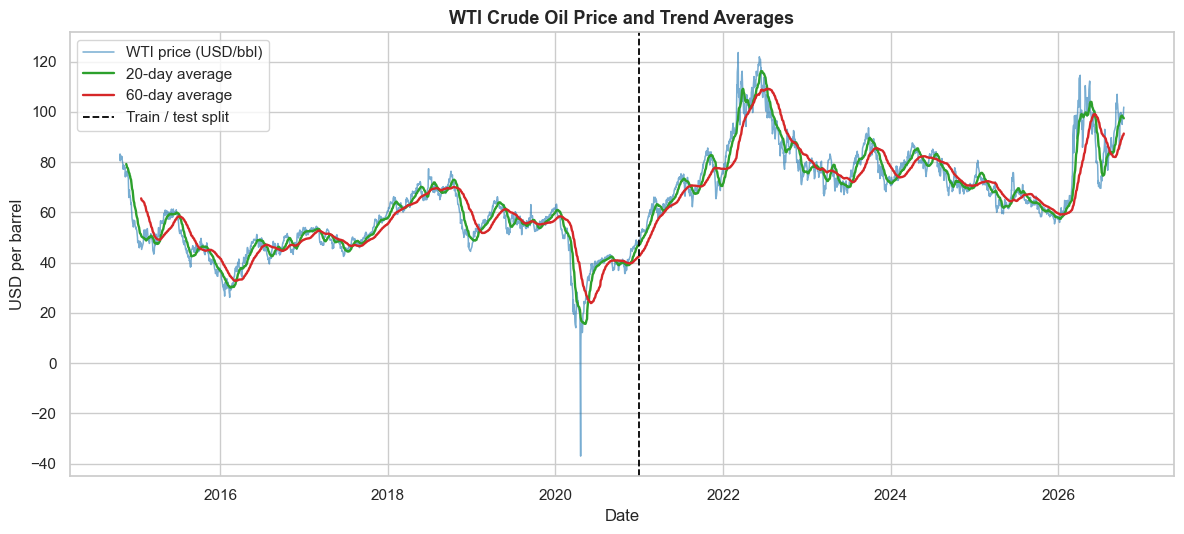

In [55]:
fig, ax = plt.subplots(figsize=(12, 5.5))
ax.plot(prices.index, prices["wti"], color="#1f77b4", alpha=0.6, lw=1.1, label="WTI price (USD/bbl)")
ax.plot(prices.index, prices["wti"].rolling(MA_FAST).mean(), color="#2ca02c", lw=1.7, label=f"{MA_FAST}-day average")
ax.plot(prices.index, prices["wti"].rolling(MA_SLOW).mean(), color="#d62728", lw=1.7, label=f"{MA_SLOW}-day average")
ax.axvline(pd.to_datetime(SPLIT_DATE), color="black", ls="--", lw=1.3, label="Train / test split")
ax.set_title("WTI Crude Oil Price and Trend Averages")
ax.set_xlabel("Date")
ax.set_ylabel("USD per barrel")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

> **How to read this chart**: When the green line is above the red line the trend strategy holds WTI; when it falls below, the strategy sits in cash. The dashed line separates the in-sample period (left) from the out-of-sample period (right). The brief dip below zero in spring 2020 is the negative-price event.

### Step 20: Chart 2, growth of 1.00 (WTI trend, out-of-sample)

**WHAT**: Growth of 1.00 invested on the first test day, for all four versions plus buy-and-hold.

**WHY**: Shows compounding and stability across risk regimes in one picture.

**WATCH OUT**: Every line starts at exactly 1.00 for a fair comparison.

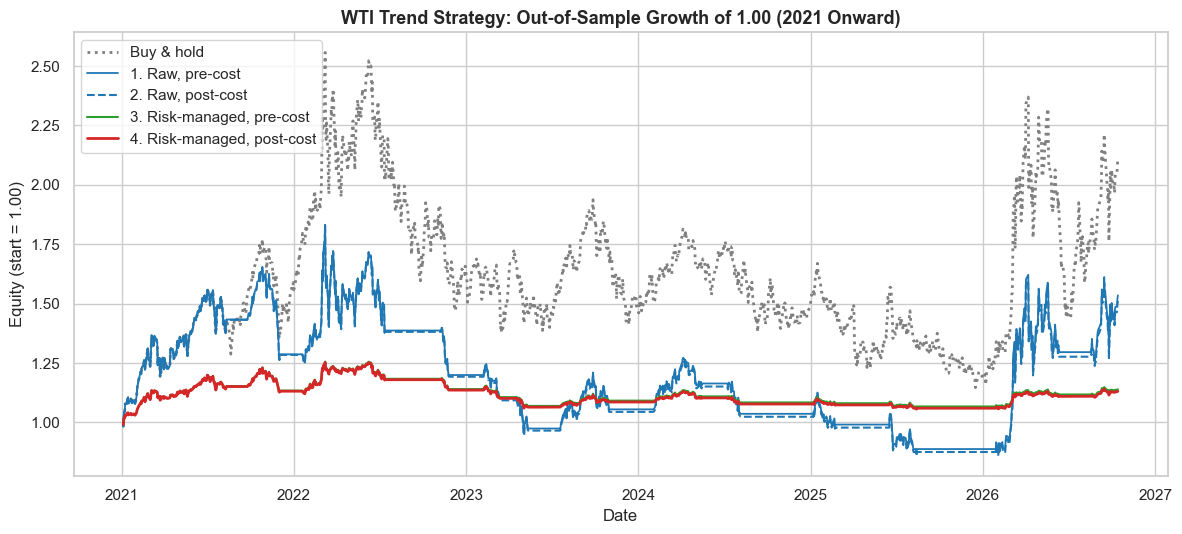

In [56]:
w_raw, g_raw, n_raw = run_one("WTI trend", is_test, risk_managed=False)
w_risk, g_risk, n_risk = run_one("WTI trend", is_test, risk_managed=True)
bh_wti = returns["wti"][is_test]

fig, ax = plt.subplots(figsize=(12, 5.5))
ax.plot(bh_wti.index, (1 + bh_wti).cumprod(), color="gray", ls=":", lw=2, label="Buy & hold")
ax.plot(g_raw.index, (1 + g_raw).cumprod(), color="#1f77b4", lw=1.3, label="1. Raw, pre-cost")
ax.plot(n_raw.index, (1 + n_raw).cumprod(), color="#1f77b4", ls="--", lw=1.5, label="2. Raw, post-cost")
ax.plot(g_risk.index, (1 + g_risk).cumprod(), color="#2ca02c", lw=1.5, label="3. Risk-managed, pre-cost")
ax.plot(n_risk.index, (1 + n_risk).cumprod(), color="#d62728", lw=2, label="4. Risk-managed, post-cost")
ax.set_title("WTI Trend Strategy: Out-of-Sample Growth of 1.00 (2021 Onward)")
ax.set_xlabel("Date")
ax.set_ylabel("Equity (start = 1.00)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

> **How to read this chart**: The higher a line ends, the more it earned; the smoother it is, the less risky. Notice whether the trend strategies ever overtook the grey buy-and-hold line, and how much calmer the risk-managed lines are.

### Step 21: Chart 3, drawdowns (WTI trend, out-of-sample)

**WHAT**: How far each version sat below its previous peak over time.

**WHY**: Exposes how deep and how long the losing stretches were, which a final return number hides.

**WATCH OUT**: Drawdown is 0 at new highs and negative otherwise. Deeper means worse.

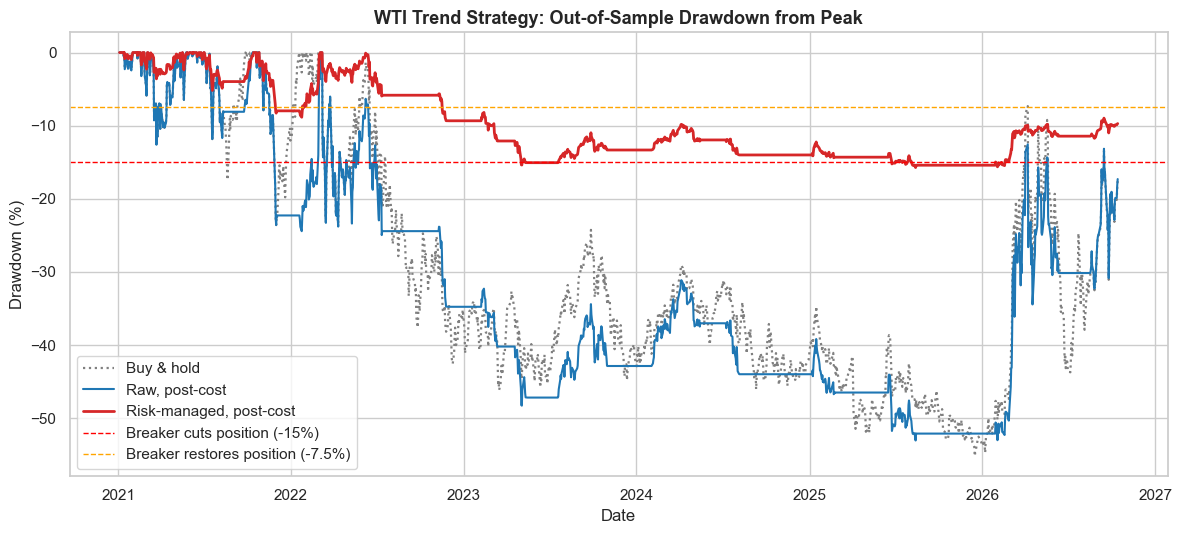

In [57]:
def drawdown_series(returns_series):
    equity = (1 + returns_series).cumprod()
    return equity / equity.cummax() - 1


fig, ax = plt.subplots(figsize=(12, 5.5))
ax.plot(bh_wti.index, drawdown_series(bh_wti) * 100, color="gray", ls=":", lw=1.6, label="Buy & hold")
ax.plot(n_raw.index, drawdown_series(n_raw) * 100, color="#1f77b4", lw=1.5, label="Raw, post-cost")
ax.plot(n_risk.index, drawdown_series(n_risk) * 100, color="#d62728", lw=2, label="Risk-managed, post-cost")
ax.axhline(DD_CUT * 100, color="red", ls="--", lw=1, label=f"Breaker cuts position ({DD_CUT:.0%})")
ax.axhline(DD_RECOVER * 100, color="orange", ls="--", lw=1, label=f"Breaker restores position ({DD_RECOVER:.1%})")
ax.set_title("WTI Trend Strategy: Out-of-Sample Drawdown from Peak")
ax.set_xlabel("Date")
ax.set_ylabel("Drawdown (%)")
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

> **How to read this chart**: Each dip is a losing stretch. The red line should stay much shallower than the others, and it may dip slightly past the dashed breaker line because the breaker only reacts after the fall and trades on the following day.

### Step 22: Chart 4, rolling volatility (WTI trend, out-of-sample)

**WHAT**: 20-day annualized volatility of the raw and risk-managed versions, against the 10% target.

**WHY**: Checks that volatility targeting actually steadies risk.

**WATCH OUT**: Realized volatility can sit **below** the target, because the strategy is in cash part of the time and the 1.5x cap limits calm-period sizing.

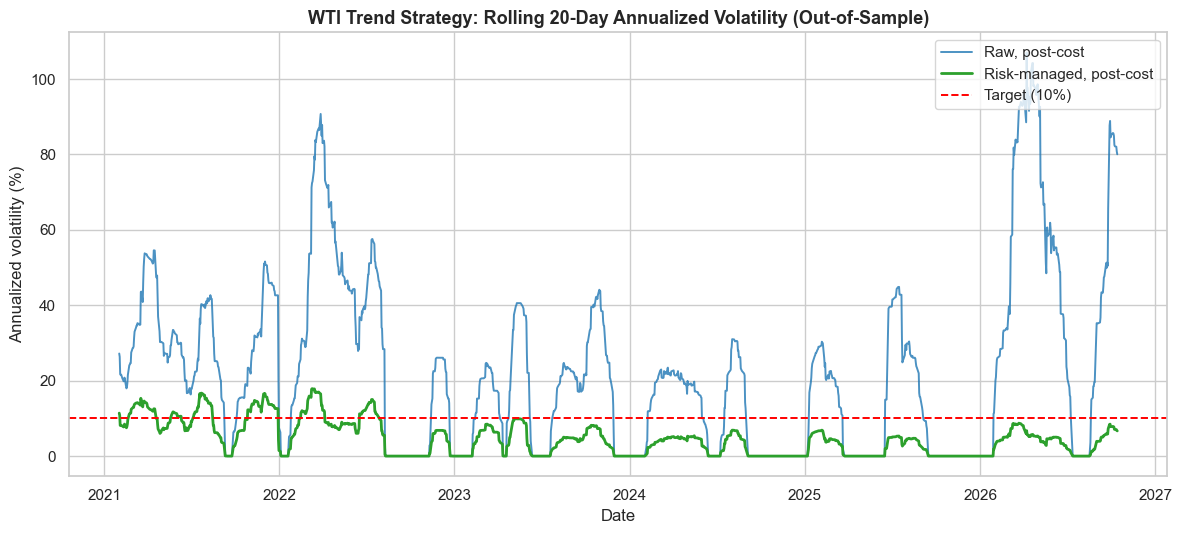

In [58]:
rolling_raw = n_raw.rolling(VOL_WINDOW).std() * np.sqrt(TRADING_DAYS) * 100
rolling_risk = n_risk.rolling(VOL_WINDOW).std() * np.sqrt(TRADING_DAYS) * 100

fig, ax = plt.subplots(figsize=(12, 5.5))
ax.plot(rolling_raw.index, rolling_raw, color="#1f77b4", alpha=0.8, lw=1.4, label="Raw, post-cost")
ax.plot(rolling_risk.index, rolling_risk, color="#2ca02c", lw=2, label="Risk-managed, post-cost")
ax.axhline(TARGET_VOL * 100, color="red", ls="--", lw=1.4, label=f"Target ({TARGET_VOL:.0%})")
ax.set_title(f"WTI Trend Strategy: Rolling {VOL_WINDOW}-Day Annualized Volatility (Out-of-Sample)")
ax.set_xlabel("Date")
ax.set_ylabel("Annualized volatility (%)")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

> **How to read this chart**: The green line should stay far below the blue line. It tracks the target loosely rather than exactly; sizing uses *past* volatility, so sudden jumps cause temporary overshoots, and days in cash pull it lower.

### Step 23: Chart 5, the Brent-WTI spread and its z-score

**WHAT**: Top: the spread in dollars. Bottom: its 60-day z-score with the entry (+/-2) and exit (+/-0.5) bands.

**WHY**: Shows when the strategy considers the gap abnormal and where positions come from.

**WATCH OUT**: The spike in April 2020 (the negative WTI price) distorts the z-score for the following weeks. Also note that in 2026 the gap in this data widens far beyond its usual range, so the rule is tested in an unusual regime there.

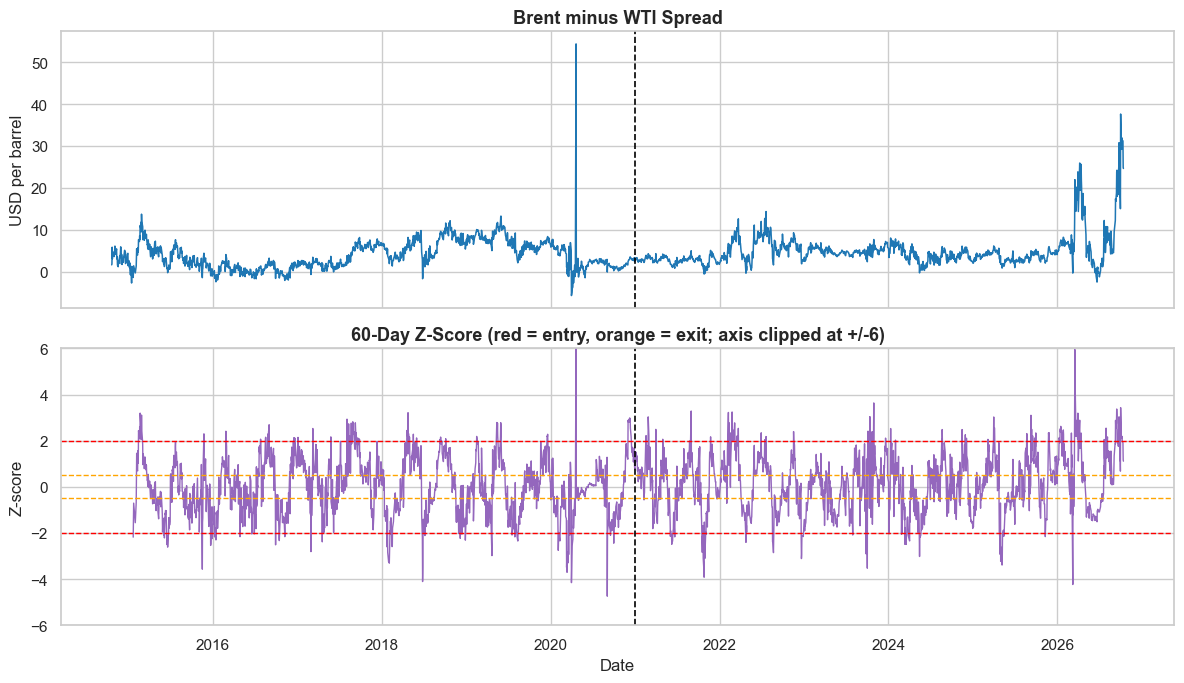

In [59]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
axes[0].plot(spread.index, spread, color="#1f77b4", lw=1.1)
axes[0].axvline(pd.to_datetime(SPLIT_DATE), color="black", ls="--", lw=1.2)
axes[0].set_title("Brent minus WTI Spread")
axes[0].set_ylabel("USD per barrel")

axes[1].plot(spread_z.index, spread_z, color="#9467bd", lw=1)
for level, color in [(Z_ENTRY, "red"), (-Z_ENTRY, "red"), (Z_EXIT, "orange"), (-Z_EXIT, "orange")]:
    axes[1].axhline(level, color=color, ls="--", lw=1)
axes[1].axvline(pd.to_datetime(SPLIT_DATE), color="black", ls="--", lw=1.2)
axes[1].set_ylim(-6, 6)
axes[1].set_title(f"{Z_WINDOW}-Day Z-Score (red = entry, orange = exit; axis clipped at +/-6)")
axes[1].set_ylabel("Z-score")
axes[1].set_xlabel("Date")
plt.tight_layout()
plt.show()

> **How to read this chart**: When the purple line crosses beyond a red band the strategy opens a position; it closes when the line returns inside the orange bands. Long stretches inside the bands mean the strategy is in cash.

### Step 24: Chart 6, all four strategies together (risk-managed, out-of-sample)

**WHAT**: Growth of 1.00 for every risk-managed strategy after costs, with gold buy-and-hold for reference.

**WHY**: One picture comparing the whole strategy set under identical risk rules.

**WATCH OUT**: All strategies are sized to the same 10% risk target, so lines are comparable. The out-of-sample period is a single market regime, so a similar picture is not guaranteed in other periods.

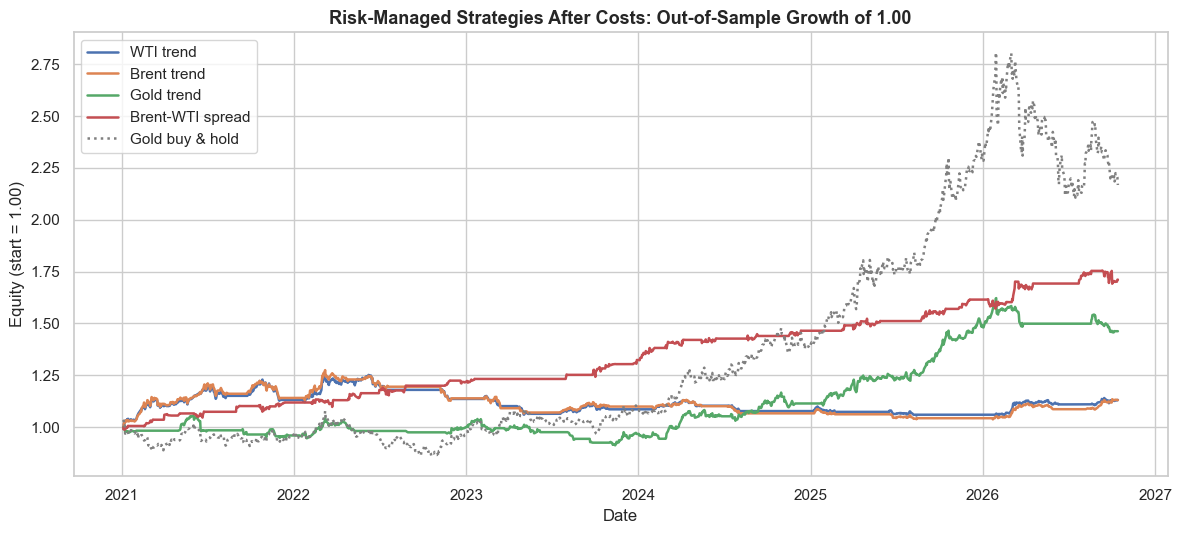

In [60]:
fig, ax = plt.subplots(figsize=(12, 5.5))
for name in signals:
    w, g, n = run_one(name, is_test, risk_managed=True)
    ax.plot(n.index, (1 + n).cumprod(), lw=1.8, label=name)
bh_gold = returns["gold"][is_test]
ax.plot(bh_gold.index, (1 + bh_gold).cumprod(), color="gray", ls=":", lw=1.8, label="Gold buy & hold")
ax.set_title("Risk-Managed Strategies After Costs: Out-of-Sample Growth of 1.00")
ax.set_xlabel("Date")
ax.set_ylabel("Equity (start = 1.00)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

> **How to read this chart**: Compare how steeply each line climbs and how smooth it is. Lines that look suspiciously smooth deserve extra scrutiny (see the robustness checks in Step 17).

## 9. Findings and Limitations

> **Draft written from this notebook's actual output (data through 2026-10-14).** Rewrite it in your own words before using it in an interview, and re-check any number if you change the data or settings. All figures are out-of-sample (2021 onward) and after costs unless stated.

### 1. How did the strategies do against simply holding the asset?

- **Oil trend (WTI, Brent): did not beat buy-and-hold.** WTI trend (raw) returned 51.1% with Sharpe 0.39, versus 110.8% and 0.53 for buy-and-hold. Brent shows the same pattern (49.6% vs 147.1%). The raw rules also did not protect against drawdowns: WTI -53.0% vs -55.2%, and Brent was *worse* (-61.5% vs -55.0%).
- **When it worked and when it did not:** WTI trend gained in 2021 (28.4%) and 2026 so far (72.6%), the two strong one-way years, and lost money in every year from 2022 to 2025 (-7.2%, -12.4%, -2.0%, -14.5%). That is the classic trend-following pattern: it pays in strong trends and bleeds in choppy markets. The total return rests on very few periods.
- **Gold trend: closer, still behind.** Raw gold trend returned 85.5% (Sharpe 0.77, drawdown -20.1%) versus 116.8% (Sharpe 0.82, drawdown -24.9%) for holding. It lagged on return but with a shallower drawdown. Most of its gain came in 2024 and 2025, a sustained gold rally that suits trend rules.
- **Brent-WTI spread: strongest result, but treat with caution** (see point 4). Raw 135.8%, Sharpe 0.92; risk-managed 71.1%, Sharpe 1.43, max drawdown only -3.6%. It was positive in every calendar year, with similar in-sample results (risk-managed Sharpe 1.17).

### 2. What did the risk rules do, and what did they cost?

Each cell shows **raw → risk-managed** (volatility targeting plus drawdown circuit breaker):

| Strategy | Total return | Sharpe | Max drawdown | Volatility |
|---|---|---|---|---|
| WTI trend | 51.1% → 13.1% | 0.39 → 0.36 | -53.0% → -15.7% | 32.6% → 6.6% |
| Brent trend | 49.6% → 13.0% | 0.38 → 0.36 | -61.5% → -18.6% | 33.0% → 6.8% |
| Gold trend | 85.5% → 46.3% | 0.77 → 0.80 | -20.1% → -13.7% | 15.9% → 9.0% |
| Brent-WTI spread | 135.8% → 71.1% | 0.92 → 1.43 | -21.0% → -3.6% | 18.6% → 6.9% |

- **Drawdowns fell sharply for every strategy**, and volatility moved close to or below the 10% target. This is the clearest benefit of the risk rules.
- **Return was given up** in exchange (the oil trend strategies lost most of their return), and for WTI and Brent the Sharpe ratio actually **fell slightly** (0.39 → 0.36 for WTI). So for oil the rules bought safety, not better risk-adjusted performance. For gold and the spread, Sharpe **rose**.
- Volatility ended below the 10% target partly because the strategies sit in cash part of the time.

### 3. Is the oil trend rule robust? (in-sample check)

- Before 2021, WTI trend (raw) had a Sharpe of only 0.12 against 0.33 for buy-and-hold, and the risk-managed version **lost** 9.9%. So there was no convincing in-sample edge for the 20/60 rule on WTI.
- The window grid (Step 17) agrees: WTI in-sample Sharpe ranges only from -0.24 to 0.31, positive in 13 of 19 window pairs, with no broad strong area. Gold's ranges from 0.30 to 0.68 and is positive in 19 of 19, a much more stable picture.
- **Honest conclusion:** the WTI out-of-sample profit mainly reflects the 2021 and 2026 rallies, not a proven edge. The 20/60 windows were conventional defaults, not optimised.

### 4. How much do costs matter, and is the spread result fragile?

- **Costs:** at 20 basis points, WTI trend (raw) still returned 44.3% (Sharpe 0.36), because it trades rarely (about 31 position changes in 5.8 years). The spread trades about 85 times, so it is more sensitive: its risk-managed Sharpe falls from 1.43 to 0.93 at 20 bps per leg.
- **Execution delay is the bigger warning for the spread.** Its risk-managed Sharpe is 1.43 with a 1-day delay, 0.73 with 2 days and 0.58 with 3 days (raw: 0.92 → 0.46 from day 1 to day 2). The trend strategies barely change with delay. A fast-decaying edge is a typical sign of data-timing effects: Brent and WTI prices are recorded at different times of day, which can make day-to-day spread moves look more predictable than they are. Together with the unusually smooth results (positive every year, drawdown of only 3.6%), **treat the spread result as unvalidated** until it is tested on same-time prices from tradable futures.

### 5. Do US crude inventories explain oil price moves?

- **Same week (Test A, not tradable):** weak. Spearman correlation -0.054 (t-statistic -1.3), too small to rule out chance.
- **Release-day reaction (Test B):** small but in the expected direction. Spearman correlation -0.148 (t-statistic -3.7), and WTI averaged 0.39% on days when a draw was reported versus -0.12% for builds (t-statistic of the difference 1.73, below the usual threshold of 2). The ordinary correlation is near zero (-0.002) mainly because of extreme days such as April 2020; excluding days beyond +/-15% it is -0.108.
- **Conclusion:** the reaction exists but is small, and the raw inventory change is a weak signal on its own. Markets react to the surprise versus forecasts, which this data does not include, so a proper test needs consensus forecasts.

### 6. Limitations

1. **Spot/continuous prices, not futures.** No contract expiry, rolling (and roll yield in contango or backwardation), margin or financing. The cost of carry is $F = S \cdot e^{(r + u - y)T}$, with $r$ the interest rate, $u$ storage cost and $y$ convenience yield.
2. **Gold series.** Confirm and state exactly which gold series `gold.csv` is (spot, futures or an ETF); the notebook only assumes a daily USD-per-ounce price.
3. **One market regime in the test period.** The out-of-sample window is dominated by a few large oil and gold moves, and in 2026 the Brent-WTI gap widens far beyond its historical range; a different period could look very different.
4. **Simple cost model.** Fixed 5 basis points per unit traded; no slippage, borrowing cost or market impact. Real costs for spreads are usually higher.
5. **Parameters are conventional defaults, neither optimised nor proven.** The window grid is a sensitivity check, not a search, and no walk-forward re-estimation was done.
6. **April 2020 is a modelling assumption.** WTI and spread returns are set to zero on 20-21 April 2020. This avoids meaningless percentages, but it is not the actual market P&L for those days: it removes the real wipe-out a long WTI holder suffered on 20 April from the in-sample buy-and-hold figures, and it leaves out a large dollar gain a short-spread position would have made on 21 April. The out-of-sample results (2021 onward) are not affected.
7. **Risk-free rate set to 0%**, which slightly flatters Sharpe ratios. Sharpe also treats up and down moves alike and says little about rare extreme losses.
8. **Inventory tests** use the change itself, not a surprise versus forecasts.

### 7. Possible next steps

- Test on real futures data with a documented roll method.
- Add a government bond ETF as a fixed-income asset.
- Re-run the spread test with synchronized prices to settle the delay question.
- Replace the single split with walk-forward testing (train on a window, test on the next, slide forward).
- Add the inventory *surprise* once forecast data is available.

### 8. A 30-second summary you can say out loud

"I tested a 20/60-day trend rule on WTI, Brent and gold, and a mean-reversion rule on the Brent-WTI spread, with a one-day execution delay, 10% volatility targeting, a drawdown circuit breaker and transaction costs. I fixed the settings before testing and judged only the 2021-onward period. The oil trend rules did not beat buy-and-hold (51.1% vs 110.8% for WTI) and made money only in a couple of strong years; the risk rules cut the WTI drawdown from -53.0% to -15.7%. The spread strategy looked best (Sharpe 1.43), but its edge roughly halved with one extra day of delay, so I treat it as unproven. The main limits are that I used spot prices, not futures, and one market regime."